# Практика №2

На прошлой практике мы реализовали DTW алгоритм. Он очень хорош и вроде как даже где-то применяется. Но у него есть существенные недостатки:

1) Для распознавания какого-либо слова необходимо иметь заранее подготовленные эталонные записи. Из этого вытекает проблема масштабирования системы с большим словарем.<br>
2) Подобная система имеет плохую устойчивость к шумам.<br>
3) По какому принципу вибирать нужные эталоны?<br>
4) Сколько должно быть таких эталонов, чтобы покрыть всю вариативность произнесеней?<br>
5) Чем больше эталонов, тем алгоритм вычислительнозатратен.<br>

В этом уроке мы перейдем от DTW к распознаванию по эталонному словарю. 

Эталон в графе теперь будет задаваться как последовательность фонем из словаря. Словарь для YES_NO (data/lexicon_yes_no.txt) выглядит следующим образом:

<b>YES</b>  SIL Y EH1 S SIL<br>
<b>NO</b>  SIL N OW1 SIL<br>

Словарь для цифр (data/lexicon_digits.txt):

<b>ZERO</b>  SIL Z IH1 R OW0 SIL<br>
<b>ZERO</b>  SIL Z IY1 R OW0 SIL<br>
<b>ONE</b>  SIL W AH1 N SIL<br>
<b>ONE</b>  SIL HH W AH1 N SIL<br>
<b>TWO</b>  SIL T UW1 SIL<br>
<b>THREE</b>  SIL TH R IY1 SIL<br>
<b>FOUR</b>  SIL F AO1 R SIL<br>
<b>FIVE</b>  SIL F AY1 V SIL<br>
<b>SIX</b>  SIL S IH1 K S SIL<br>
<b>SEVEN</b>  SIL S EH1 V AH0 N SIL<br>
<b>EIGHT</b>  SIL EY1 T SIL<br>
<b>NINE</b>  SIL N AY1 N SIL<br>

SIL здесь – это фонема паузы.
Как вы возможно заметили, для некторых слов имеется несколько вариантов фонемной транскрипции. Это позволяет лучше учесть фонетическое разнообразие в произнесении некоторых слов.

Каждой фонеме будет сопоставлен наиболее типичный для нее вектор признаков. В данном случае мы будем использовать среднее значение вектора признаков фонем, взятых из обучающего набора. Будем назвать это акустической моделью.

### Данные для обучения

Наша задача собрать статистику акустических признаков по каждой фонеме, находящейся в графе распознавания. В качестве обучающей выборки мы будем использовать подмножество данных librispeech (аудиозаписи чтения книг на английском). Для этого предварительно мной была получена покадровая разметка этого подмножества на фонемы. Схематично данный процесс представлен на картинке ниже:

![](https://drive.google.com/uc?export=view&id=16PdwggV_Cl6aaD4cu1MZ-fKzWzAvcFVw)

Файл разметки (ali_phones.txt) представлен в формате:

<b>filename1 phone_frame1 phone_frame2 phone_frame3 ...<br>
   filename2 phone_frame1 phone_frame2 phone_frame3 ...</b> 
   
Пример такой покадровой фонемной разметки одного файла с текстом "<b>MUCH COULD BE DONE IN THREE YEARS</b>" представлен ниже:

<b>1183-124566-0003 SIL SIL SIL SIL SIL SIL SIL SIL SIL SIL SIL SIL SIL SIL SIL SIL M M M M M M M M M AH1 AH1 AH1 AH1 AH1 AH1 AH1 AH1 AH1 CH CH CH CH CH CH CH CH CH CH CH K K K K
K K K K K UH1 UH1 UH1 UH1 D D D D D B B B B B B IY0 IY0 IY0 IY0 IY0 D D D D D D D D D D D D AH1 AH1 AH1 AH1 AH1 AH1 AH1 AH1 AH1 AH1 AH1 AH1 AH1 AH1 AH1 AH1 AH1 AH1 AH1 AH1 N N
N N N N N N N N N N N N N SIL SIL SIL SIL SIL SIL SIL SIL SIL SIL SIL SIL SIL SIL SIL SIL SIL SIL SIL SIL SIL SIL SIL SIL SIL SIL SIL SIL SIL SIL SIL SIL SIL SIL SIL SIL SIL SI
L SIL SIL SIL SIL SIL SIL SIL SIL IH1 IH1 IH1 IH1 IH1 IH1 IH1 IH1 IH1 IH1 IH1 N N N N N N N N N N SIL SIL SIL SIL SIL TH TH TH TH TH TH TH TH TH TH TH TH TH R R R R R R IY1 IY1
 IY1 IY1 IY1 IY1 IY1 Y Y Y Y Y Y Y Y Y Y Y Y Y Y Y Y Y Y IH1 IH1 IH1 IH1 IH1 IH1 IH1 IH1 R R R R R R R R R R R R R R R Z Z Z Z Z Z Z Z Z Z Z Z Z Z Z Z Z Z Z Z SIL SIL SIL SIL</b>
 
Аудио файлы этих данных лежат в папке "data/train_librispeech_10h/wav_dir"

### Bootstrap

In [ ]:
!gdown --id '1meikF0XqBUnVZKoY3160MQ0R25lq-EMu'
!gdown --id '1f0LkW6I3Q5CnOThuNFAJ9umgnb2eU4Ox'

Downloading...
From: https://drive.google.com/uc?id=1meikF0XqBUnVZKoY3160MQ0R25lq-EMu
To: /content/lab2.zip
100% 1.66M/1.66M [00:00<00:00, 50.4MB/s]
Downloading...
From: https://drive.google.com/uc?id=1f0LkW6I3Q5CnOThuNFAJ9umgnb2eU4Ox
To: /content/train_librispeech_10h.zip
679MB [00:11, 60.7MB/s]


In [ ]:
!unzip -q lab2.zip
!unzip -q train_librispeech_10h.zip
!mv train_librispeech_10h lab2/data
!rm -rf lab2.zip sample_data train_librispeech_10h.zip
%cd lab2

/content/lab2


In [ ]:
import os
import numpy as np
import time
from tqdm.notebook import tqdm
import matplotlib.pyplot as plt
import IPython.display as ipd
import librosa, librosa.display
 
from sklearn.manifold import TSNE
from sklearn.mixture import GaussianMixture

In [ ]:
#@markdown Plotting style (default is styled like plots from [FiveThirtyeight.com](https://fivethirtyeight.com/))
matplotlib_style = 'fivethirtyeight' #@param ['fivethirtyeight', 'bmh', 'ggplot', 'seaborn', 'default', 'Solarize_Light2', 'classic', 'dark_background', 'seaborn-colorblind', 'seaborn-notebook']
import matplotlib.pyplot as plt
plt.style.use(matplotlib_style)
%matplotlib inline
plt.rcParams['image.interpolation'] = 'nearest'
plt.rcParams['image.cmap'] = 'gray'
 
#@markdown Resolution of the plot outputs (`retina` is the highest resolution)
notebook_screen_res = 'retina' #@param ['retina', 'png', 'jpeg', 'svg', 'pdf']
%config InlineBackend.figure_format = notebook_screen_res

In [ ]:
# рассмотрим пример такой записи:
wav_example = 'data/train_librispeech_10h/wav_dir/1183-124566-0003.flac'
 
# чтение wav файла:
x, sr = librosa.load(wav_example, sr=None)     # sr=None to preserve the native sampling rate
 
print('Number of samples: {}'.format(len(x)))
print('Sampling rate: {} Hz'.format(sr))
print('Duration: {:.2f} s'.format(len(x)/sr))  # ~ librosa.get_duration(x, sr)
 
# воспроизведение:
ipd.Audio(x, rate=sr)

Number of samples: 45680
Sampling rate: 16000 Hz
Duration: 2.85 s


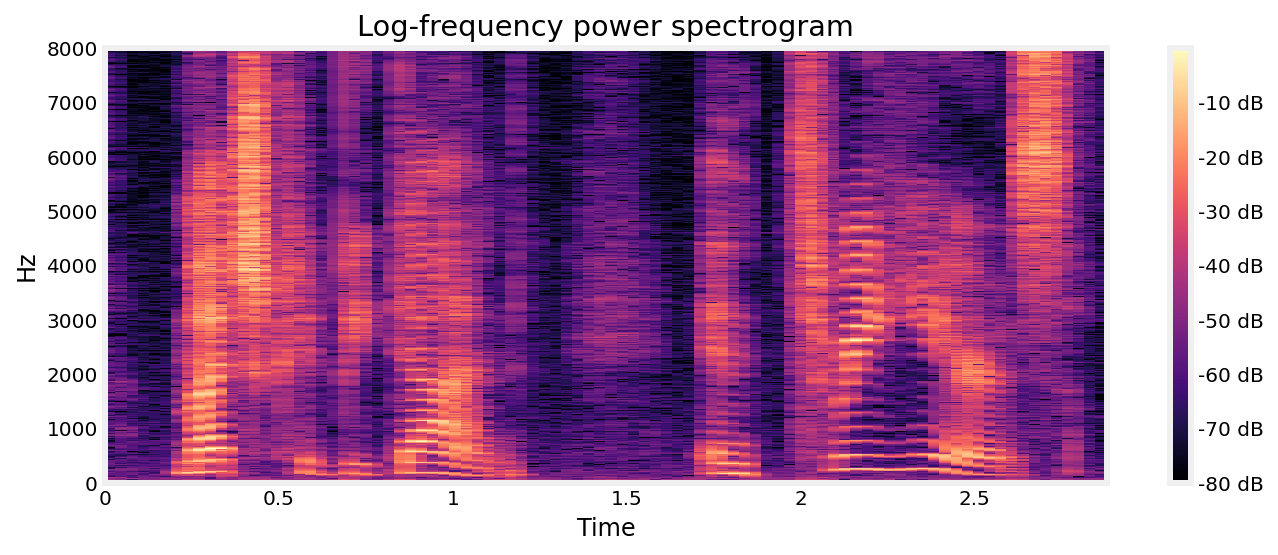

In [ ]:
# спектрограмма:
D = librosa.amplitude_to_db(np.abs(librosa.stft(x)), ref=np.max)
plt.figure(figsize=(10, 4))
librosa.display.specshow(D, sr=sr, y_axis='hz', x_axis='time')
plt.colorbar(format='%+2.0f dB')
plt.title('Log-frequency power spectrogram');

### Подготовка данных

In [ ]:
# загрузка покадровой фонемной разметки в словарь:
def load_phone_aligment(aligment_file):
    ali_dict = {}
    with open(aligment_file, encoding='utf-8') as fn:
        for line in fn:
            line = line.strip().split()
            ali_dict[line[0]] = line[1:]
    return ali_dict
 
ali_file = 'data/train_librispeech_10h/ali_phones.txt'
ali_dict = load_phone_aligment(ali_file)

In [ ]:
# подсчет акустических признаков для записей из папки:
def load_data_dict(dir_path, count=None):
    data_dict = {}
    for step, wav_name in tqdm(enumerate(os.listdir(dir_path))):
        x, sr = librosa.load(os.path.join(dir_path, wav_name), sr=None) 
        mfcc = librosa.feature.mfcc(x, sr=sr, n_mfcc=13, 
                                    n_fft=int(sr * 0.025),
                                    hop_length=int(sr * 0.01))
        if count and step == count:
            print(f'Early stop at {step}th file..')
            break
        data_dict[wav_name.split('.')[0]] = mfcc.T  
    return data_dict
 
train_records_dir = 'data/train_librispeech_10h/wav_dir'
train_data_dict = load_data_dict(train_records_dir, count=100)

Early stop at 100th file..


In [ ]:
# инициализация списка допустимых фонем из предустановленного файла
def init_phones_dict(phones_file):
    phones_dict = {}
    with open(phones_file, encoding='utf-8') as fn:
        for line in fn:
            phones_dict[line.strip()] = []
    return phones_dict
 
phones_file = 'data/train_librispeech_10h/phones'
phones_dict = init_phones_dict(phones_file)

In [ ]:
# присвоим каждой фонеме набор ее признаков в соответствии с фонемной разметкой обучающей выборки
# количество кадров признаков может немного отличаться от количества размеченных фонем
# это связано с особенностми построения разметки в Kaldi
for file_name in train_data_dict.keys():
    file_feats = train_data_dict[file_name]
    file_ali = ali_dict[file_name]
    for frame in range(min(len(file_feats), len(file_ali))):
        phones_dict[file_ali[frame]].append(file_feats[frame])
        
# выведем статистику по каждой фонеме (некоторые фонемы вообще не используются, это особенности разметки в Kaldi):
count = 0
for phone in phones_dict.keys():
    if len(phones_dict[phone]) == 0:
        count +=1
    print(f'{phone:<3}: {len(phones_dict[phone])}')
print(f'Number of empty phones is: {count}')

SIL: 23159
SPN: 542
AA : 0
AA0: 28
AA1: 1690
AA2: 57
AE : 0
AE0: 17
AE1: 3811
AE2: 115
AH : 0
AH0: 5687
AH1: 1936
AH2: 64
AO : 0
AO0: 26
AO1: 1810
AO2: 96
AW : 0
AW0: 0
AW1: 988
AW2: 11
AY : 0
AY0: 47
AY1: 2672
AY2: 206
B  : 1520
CH : 850
D  : 4050
DH : 1910
EH : 0
EH0: 106
EH1: 2483
EH2: 76
ER : 0
ER0: 2266
ER1: 1044
ER2: 29
EY : 0
EY0: 53
EY1: 2308
EY2: 134
F  : 2438
G  : 834
HH : 1978
IH : 0
IH0: 2671
IH1: 2281
IH2: 104
IY : 0
IY0: 2260
IY1: 2246
IY2: 36
JH : 758
K  : 2782
L  : 4111
M  : 3177
N  : 6243
NG : 1299
OW : 0
OW0: 222
OW1: 2081
OW2: 99
OY : 0
OY0: 0
OY1: 217
OY2: 0
P  : 1969
R  : 3592
S  : 6826
SH : 1424
T  : 6252
TH : 869
UH : 0
UH0: 0
UH1: 338
UH2: 8
UW : 0
UW0: 80
UW1: 1553
UW2: 31
V  : 1774
W  : 1962
Y  : 713
Z  : 3304
ZH : 51
Number of empty phones is: 19


In [ ]:
# соберем статистику на основе среднего значения для каждой фонемы
mean_phones_value = {}
for phone in phones_dict.keys():
    if phones_dict[phone]:
        mean_phones_value[phone] = np.mean(phones_dict[phone], axis=0)

In [ ]:
#-----------------------------TODO №2-----------------------------------
# построить GMM модель для каждой фонемы (смотри задание2)
phones_gmm = {}
for phone in phones_dict.keys():
    if phones_dict[phone]:
        gmm = GaussianMixture(n_components=3, tol=1e-3, random_state=0, 
                              covariance_type='spherical')
        phones_gmm[phone] = gmm.fit(phones_dict[phone])
#-----------------------------------------------------------------------

### Инициализация фонемного графа

In [ ]:
# теперь будем распознавать по словарю, состоящему из конечных слов
# для этого нужно загрузить файл лексикона, который определяет из каких фонем состоят наши слова
def load_lexicon_dict(lexicon_file):
    lexicon_dict = {}
    with open(lexicon_file, encoding='utf-8') as fn:
        for line in fn:
            line = line.strip().split()
            lexicon_dict[line[0]] = line[1:]
    return lexicon_dict
 
lexicon_file = 'data/lexicon_yes_no.txt'
lexicon_dict = load_lexicon_dict(lexicon_file)

Узлы графа теперь представляют собой отдельные фонемы с переходом только в себя и следующий узел (переходов через несколько узлов уже не будет, так как пропуск фонемы в слове нежелателен). Схема такого графа для да/нет (для цифр по аналогии) представлена ниже:

![](https://drive.google.com/uc?export=view&id=1IJhR0l0YCPDge05ohigs0_P5gDX66fdM)

В качестве <b>model</b> мы будем хранить простой класс <b>AcousticModel</b>, который хранит в себе имя фонемы и ее среднее значение. Также у этого класса есть метод вычисления евклидовой дистанции от хранящегося в нем среднего значения признака фонемы до текущего признака распознаваемой записи, который передается этому методу. 

In [ ]:
class AcousticModel:
    def __init__(self, phone_name, phone_feats):
        self.phone_name = phone_name
        self.phone_feats = phone_feats
    def distance(self, input_feats):
        return float(np.sqrt(sum(pow(self.phone_feats - input_feats, 2))))
 
#-----------------------------TODO №2--------------------------------------------
# заменить акустическую модель на основе среднего значения признака на GMM модель
class GmmAcousticModel(AcousticModel):
    def distance(self, input_feats):
        return -self.phone_feats.score(input_feats.reshape(1, -1))
#--------------------------------------------------------------------------------
 
class State:
    def __init__(self, model, index):  
        self.model = model                     # вектор признаков узла
        self.is_final = False                  # является ли этот узел финальнвм в слове
        self.word = None                       # слово эталона (назначается только для финального узла)
        self.best_token = None                 # лучший токен (по минимуму дистанции) в узле
        self.current_word = None               # текущее слово эталона
        self.next_states = []                  # список следующих узлов
        self.index = index                     # индекс узла 
 
        
def load_graph(lexicon_dict, mean_phones_value):
    start_state = State(AcousticModel(None, None), 0) # !!!
    #start_state = State(GmmAcousticModel(None, None), 0) # !!!
    graph = [start_state, ]
    state_index = 1
    for word in lexicon_dict.keys():
        previous_state = start_state
        for phone in lexicon_dict[word]:
            state = State(AcousticModel(phone, mean_phones_value[phone]), state_index) # !!!
            #state = State(GmmAcousticModel(phone, phones_gmm[phone]), state_index) # !!!
            state.current_word = word           # слово эталона теперь будет храниться в каждом узле
            state.next_states.append(state)     # add loop
            previous_state.next_states.append(state)
            previous_state = state 
            graph.append(state)
            state_index += 1
        if state:
            state.word = word
            state.is_final = True
    return graph
 
 
def print_graph(graph):
    if not os.path.exists('exp'):
        os.mkdir('exp')
    with open('exp/graph.txt', 'w') as fn:
        np.set_printoptions(formatter={'float': '{: 0.1f}'.format})
        for state in graph:
            next_state_indexes = [s.index for s in state.next_states]
            fn.write("State: index={} word={} is_final={} next_state_indexes={} phone={} \n".format(
                state.index, state.word, state.is_final, next_state_indexes, state.model.phone_name))
    print("*** SEE exp/graph.txt ***")

In [ ]:
graph = load_graph(lexicon_dict, mean_phones_value) # !!!
#graph = load_graph(lexicon_dict, phones_gmm) # !!!
print_graph(graph)

*** SEE exp/graph.txt ***


In [ ]:
class Token:
    def __init__(self, state, dist=0.0, word=""):
        self.state = state       # стейт графа, в котором токен находится в текущий момент
        self.dist = dist         # общая накопленная дистанция пути, пройденного токеном
        self.word = word         # слово, которое распозналось токеном
        self.alive = True
 
 
def beam_pruning(next_tokens, threshold):   
    best_token = next_tokens[np.argmin([token.dist for token in next_tokens])]
    for token in next_tokens:
        if token.dist > best_token.dist + threshold:
            token.alive = False
    return next_tokens
 
 
def state_pruning(next_tokens):
    for token in next_tokens:  
        if not token.state.best_token:
            token.state.best_token = token
        else:
            if token.dist <= token.state.best_token.dist:
                token.state.best_token.alive = False
                token.state.best_token = token
            else:
                token.alive = False              
    # сбрасываем best_token на None для всеx узлов графа:
    for token in next_tokens:                                                   
        if token.state.best_token:                     
            token.state.best_token = None              
    return next_tokens
 
 
def recognize(filename, features, graph, recognition_results, beam_threshold):
 
    start_state = graph[0]
    active_tokens = [Token(start_state), ]
    next_tokens = []
 
    #for ftr_frame in tqdm(features, desc="recognition..."):
    for ftr_frame in features:
        for token in active_tokens:
            if token.alive:
                for transition_state in token.state.next_states:
                    new_token = Token(transition_state, token.dist, token.word)
                    new_token.dist += transition_state.model.distance(ftr_frame)
                    next_tokens.append(new_token)
        # state and beam prunings:
        next_tokens = state_pruning(next_tokens)         
        next_tokens = beam_pruning(next_tokens, beam_threshold) 
 
        active_tokens = next_tokens
        next_tokens = []                                    
        
    # поиск финальных токенов:
    final_tokens = []
    for token in active_tokens:
        if token.state.is_final and token.alive:
            final_tokens.append(token)
 
    # если нет финальных, то берем лучший из выживших:
    if len(final_tokens) != 0:
        win_token = final_tokens[np.argmin([token.dist for token in final_tokens])]
    else:
        alive_tokens = [token for token in active_tokens if token.alive]
        win_token = alive_tokens[np.argmin([token.dist for token in alive_tokens])]
        win_token.state.word = win_token.state.current_word
 
    # вывод результата DTW
    print(f"result: {filename:<27} ==> {win_token.state.word}")
 
    # совпадает ли запись с полученным эталоном:  
    record_word = filename.split('_')[0]
    etalon_word = win_token.state.word.split('_')[0]
    recognition_results.append(etalon_word.lower() == record_word)
 
    return recognition_results

In [ ]:
def run_recognizer(records_data_dict, graph, beam_threshold=10):
    start_time = time.time()
    recognition_results = []
 
    for filename in records_data_dict.keys():    
        recognition_results = recognize(filename, records_data_dict[filename], graph, recognition_results, beam_threshold)
 
    print("-" * 60)
    print(f"WER is: {(1 - sum(recognition_results)/len(recognition_results))*100:.2f}%")
    print(f"Total time is: {time.time() - start_time:.2f} sec")
    print("-" * 60)

In [ ]:
def load_data_dict(dir_path):
    data_dict = {}
    for wav_name in os.listdir(dir_path):
        x, sr = librosa.load(os.path.join(dir_path, wav_name), sr=None) 
        mfcc = librosa.feature.mfcc(x, sr=sr, n_mfcc=13, 
                                    n_fft=int(sr * 0.025),
                                    hop_length=int(sr * 0.01))
        data_dict[wav_name] = mfcc.T
    
    return data_dict

### Запустим наше распознавание на базе YES_NO

In [ ]:
lexicon_file = 'data/lexicon_yes_no.txt'
lexicon_dict = load_lexicon_dict(lexicon_file)
graph = load_graph(lexicon_dict, mean_phones_value) # !!!
#graph = load_graph(lexicon_dict, phones_gmm) # !!!
records_data_dict = load_data_dict("data/yes_no/records")
 
run_recognizer(records_data_dict, graph, beam_threshold=10)

result: no_49af4432_nohash_0.wav    ==> NO
result: yes_39a12648_nohash_0.wav   ==> YES
result: no_ad89eb1e_nohash_0.wav    ==> NO
result: no_41474817_nohash_0.wav    ==> NO
result: yes_fc94edb0_nohash_0.wav   ==> YES
result: yes_ff63ab0b_nohash_0.wav   ==> YES
result: no_4394fc7c_nohash_0.wav    ==> NO
result: no_4abb2400_nohash_0.wav    ==> NO
result: yes_39a6b995_nohash_0.wav   ==> NO
result: yes_fe1916ba_nohash_0.wav   ==> NO
------------------------------------------------------------
WER is: 20.00%
Total time is: 0.09 sec
------------------------------------------------------------


### Запустим наше распознавание на базе Digits

In [ ]:
lexicon_file = 'data/lexicon_digits.txt'
lexicon_dict = load_lexicon_dict(lexicon_file)
graph = load_graph(lexicon_dict, mean_phones_value) # !!!
#graph = load_graph(lexicon_dict, phones_gmm) # !!!
records_data_dict = load_data_dict("data/digits/records")
 
run_recognizer(records_data_dict, graph, beam_threshold=100)

result: six_ffbb695d_nohash_0.wav   ==> FIVE
result: zero_f852895b_nohash_0.wav  ==> THREE
result: eight_daf230ac_nohash_0.wav ==> THREE
result: one_ffa76c4a_nohash_0.wav   ==> NINE
result: seven_fe5c4a7a_nohash_0.wav ==> THREE
result: five_f852895b_nohash_0.wav  ==> THREE
result: five_ffd2ba2f_nohash_0.wav  ==> FIVE
result: nine_fbe51750_nohash_0.wav  ==> NINE
result: six_ffd2ba2f_nohash_0.wav   ==> SIX
result: four_fce65496_nohash_0.wav  ==> FOUR
result: three_fce96bac_nohash_0.wav ==> SEVEN
result: eight_da584bc0_nohash_4.wav ==> SEVEN
result: zero_f92e49f3_nohash_3.wav  ==> THREE
result: nine_ccea893d_nohash_0.wav  ==> NINE
result: two_fb2f3242_nohash_0.wav   ==> THREE
result: three_feb1d305_nohash_0.wav ==> THREE
result: two_fce65496_nohash_0.wav   ==> SIX
result: seven_fd32732a_nohash_0.wav ==> SIX
result: one_fc2411fe_nohash_0.wav   ==> ONE
result: four_ffbb695d_nohash_0.wav  ==> FOUR
------------------------------------------------------------
WER is: 60.00%
Total time is: 0.49

### <b>Задание №1</b> (5 баллов):
Отрисовать кластеры признаков фонем "Y EH1 S N OW1" в двухмерном пространстве. Для понижения размерности можно воспользоваться алгоритмом t-SNE -- https://scikit-learn.org/stable/modules/generated/sklearn.manifold.TSNE.html. Все пять кластеров должны помещаться на один рисунок и иметь разные цвета. Также укажите на графике какой цвет какой фонеме соответствует.  

Y phone shape: (713, 13)
EH1 phone shape: (2483, 13)
S phone shape: (6826, 13)
N phone shape: (6243, 13)
OW1 phone shape: (2081, 13)


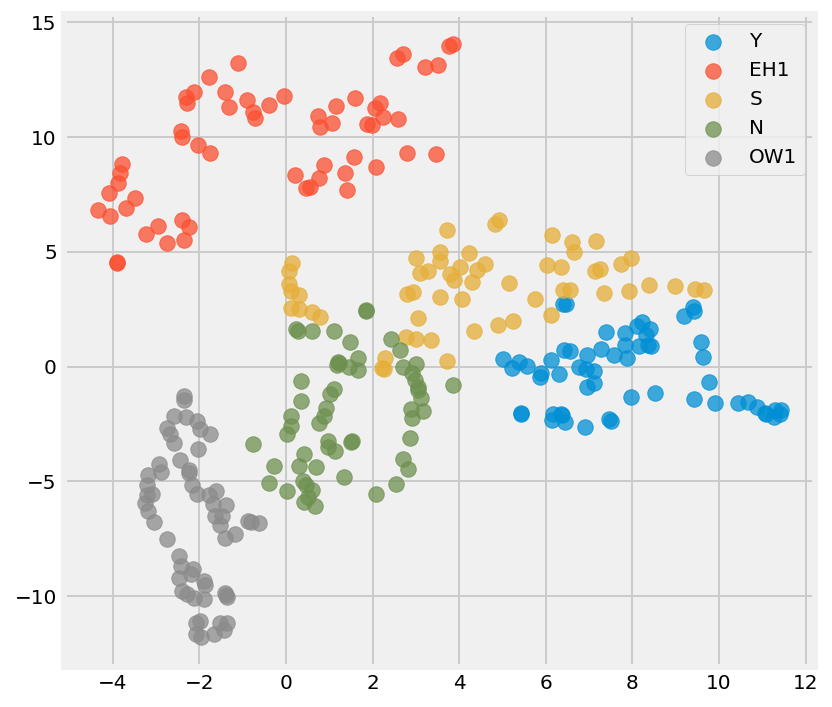

In [ ]:
fig = plt.figure(figsize=(6, 6))
#ax = fig.add_subplot(111, projection='3d') # 3d
for phone in ['Y', 'EH1', 'S', 'N', 'OW1']: # [20, 20, 25, 25, 25] train_10
    phone_oi = np.array(phones_dict[phone]) # phone of interest
    print(f'{phone} phone shape: {phone_oi.shape}')
    center = phone_oi.shape[0] // 2
    phone_oi_emb = TSNE(n_components=2, learning_rate=42, random_state=0).fit_transform(phone_oi[center-30: center+30, :])
    plt.scatter(phone_oi_emb[:, 0], phone_oi_emb[:, 1], label=phone, s=60, alpha=0.75)
    #plt.scatter(*zip(*phone_oi_emb[:, :2]), label=phone, alpha=0.75)
    #ax.scatter(*zip(*phone_oi_emb), label=phone) # 3d
plt.legend();

### <b>Задание №2</b> (5 баллов):
Заменить модель среднего значения фонемы на GMM. Количество компонент смеси для каждой фонемы можно выставить в 3. Теперь вместо расстояния мы будем измерять вероятность принадлежности кадра признаков к GMM модели фонемы, находящейся в конкретном узле графа. Чтобы использовать это значение в парадигме нашего алгоритма, в роле дистанции нам нужно брать значение -log(x), где x -- предсказанная вероятность. Тогда чем выше вероятность, тем такая импровизированная дистанция будет меньше. Ссылка на питоновскую реализацию GMM -- https://scikit-learn.org/stable/modules/generated/sklearn.mixture.GaussianMixture.html.

Что стало с качеством распознавания на двух тестах?

In [ ]:
#-----------------------------TODO №2--------------------------------------------
phones_gmm = {}
for phone in phones_dict.keys():
    if phones_dict[phone]:
        gmm = GaussianMixture(n_components=3, tol=1e-3, random_state=0, 
                              covariance_type='spherical')
        phones_gmm[phone] = gmm.fit(phones_dict[phone])
 
class GmmAcousticModel(AcousticModel):
    def distance(self, input_feats):
        #preds = self.phone_feats.predict_proba(input_feats.reshape(1, -1))
        #return (-np.log(preds[np.nonzero(preds)])).sum()
        #return float((-np.log(preds + 1e-12)).sum())
        # score() returns log-likelihood
        return -self.phone_feats.score(input_feats.reshape(1, -1))
 
def load_graph(lexicon_dict, mean_phones_value):
    start_state = State(GmmAcousticModel(None, None), 0) # !!!
    graph = [start_state, ]
    state_index = 1
    for word in lexicon_dict.keys():
        previous_state = start_state
        for phone in lexicon_dict[word]:
            state = State(GmmAcousticModel(phone, phones_gmm[phone]), state_index) # !!!
            state.current_word = word           # слово эталона теперь будет храниться в каждом узле
            state.next_states.append(state)     # add loop
            previous_state.next_states.append(state)
            previous_state = state 
            graph.append(state)
            state_index += 1
        if state:
            state.word = word
            state.is_final = True
    return graph
#--------------------------------------------------------------------------------

In [ ]:
lexicon_file = 'data/lexicon_yes_no.txt'
lexicon_dict = load_lexicon_dict(lexicon_file)
graph = load_graph(lexicon_dict, phones_gmm) # !!!
records_data_dict = load_data_dict("data/yes_no/records")
 
run_recognizer(records_data_dict, graph, beam_threshold=10)

result: no_49af4432_nohash_0.wav    ==> NO
result: yes_39a12648_nohash_0.wav   ==> YES
result: no_ad89eb1e_nohash_0.wav    ==> NO
result: no_41474817_nohash_0.wav    ==> NO
result: yes_fc94edb0_nohash_0.wav   ==> NO
result: yes_ff63ab0b_nohash_0.wav   ==> YES
result: no_4394fc7c_nohash_0.wav    ==> NO
result: no_4abb2400_nohash_0.wav    ==> NO
result: yes_39a6b995_nohash_0.wav   ==> NO
result: yes_fe1916ba_nohash_0.wav   ==> NO
------------------------------------------------------------
WER is: 30.00%
Total time is: 1.11 sec
------------------------------------------------------------


In [ ]:
lexicon_file = 'data/lexicon_digits.txt'
lexicon_dict = load_lexicon_dict(lexicon_file)
graph = load_graph(lexicon_dict, phones_gmm) # !!!
records_data_dict = load_data_dict("data/digits/records")
 
run_recognizer(records_data_dict, graph, beam_threshold=100)

result: six_ffbb695d_nohash_0.wav   ==> SIX
result: zero_f852895b_nohash_0.wav  ==> ZERO
result: eight_daf230ac_nohash_0.wav ==> ONE
result: one_ffa76c4a_nohash_0.wav   ==> ONE
result: seven_fe5c4a7a_nohash_0.wav ==> SEVEN
result: five_f852895b_nohash_0.wav  ==> FIVE
result: five_ffd2ba2f_nohash_0.wav  ==> FOUR
result: nine_fbe51750_nohash_0.wav  ==> NINE
result: six_ffd2ba2f_nohash_0.wav   ==> SIX
result: four_fce65496_nohash_0.wav  ==> ONE
result: three_fce96bac_nohash_0.wav ==> THREE
result: eight_da584bc0_nohash_4.wav ==> SIX
result: zero_f92e49f3_nohash_3.wav  ==> ZERO
result: nine_ccea893d_nohash_0.wav  ==> ONE
result: two_fb2f3242_nohash_0.wav   ==> SIX
result: three_feb1d305_nohash_0.wav ==> SIX
result: two_fce65496_nohash_0.wav   ==> ONE
result: seven_fd32732a_nohash_0.wav ==> SEVEN
result: one_fc2411fe_nohash_0.wav   ==> ONE
result: four_ffbb695d_nohash_0.wav  ==> FOUR
------------------------------------------------------------
WER is: 40.00%
Total time is: 26.61 sec
-------

Расчеты значительно замедлились, поскольку модель теперь стала гораздо сложнее.
 
Качество распознавания на первом тесте немного упало, но там и в тестовой выборке всего десять слов (неправильно распознаются теперь 3 слова из 10). 
 
На втором тесте качество распознавания значительно увеличилось (правильно распознаются 12 слов из 20). Увеличение объёма обучающей выборки должно привести к дальнейшему росту качества.